# PFE proposal A — Predictive maintenance on turbofan sensor data (NASA C-MAPSS)
Baseline: causal rolling features → gradient-boosting RUL regressor (engine-grouped CV) + Isolation-Forest health monitor with k-consecutive-cycle alarms.
Runs on CPU in ~1 min. The optional LSTM cell is marked **[GPU — Colab T4]**.
Data: NASA PCoE C-MAPSS (Saxena et al., 2008), downloaded from the public NASA mirror on AWS.

In [1]:
# Setup (Colab or local). CPU is enough unless a cell says [GPU — Colab T4].
%pip install -q scikit-learn pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


## Package source (embedded from `code/src/`, identical to the tested files)

In [2]:
import os, sys
os.makedirs('src', exist_ok=True)
os.makedirs('src/pdm', exist_ok=True)
sys.path.insert(0, os.path.abspath('src'))

In [3]:
%%writefile src/pdm/__init__.py
"""Predictive maintenance starter kit: C-MAPSS RUL regression + Isolation-Forest health monitoring."""
from . import data, evaluate, features, models  # noqa: F401
from .pipeline import run_baseline  # noqa: F401


Writing src/pdm/__init__.py


In [4]:
%%writefile src/pdm/data.py
"""Data access for NASA C-MAPSS turbofan run-to-failure data (+ a synthetic stand-in for tests).

Source (public, NASA PCoE repository mirror on AWS):
https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip
Reference: Saxena et al., 2008, doi:10.1109/PHM.2008.4711414
"""
from __future__ import annotations

import io
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

CMAPSS_URL = "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip"
COLUMNS = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]


def download_cmapss(dest: str | Path = "data/cmapss", url: str = CMAPSS_URL) -> Path:
    """Download and extract the C-MAPSS text files into `dest` (idempotent)."""
    dest = Path(dest)
    if (dest / "train_FD001.txt").exists():
        return dest
    dest.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(url, timeout=120) as r:
        outer = zipfile.ZipFile(io.BytesIO(r.read()))
    inner_name = next(n for n in outer.namelist() if n.endswith("CMAPSSData.zip"))
    inner = zipfile.ZipFile(io.BytesIO(outer.read(inner_name)))
    for n in inner.namelist():
        if n.endswith(".txt"):
            (dest / Path(n).name).write_bytes(inner.read(n))
    return dest


def _read_txt(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep=r"\s+", header=None)
    df = df.iloc[:, : len(COLUMNS)]
    df.columns = COLUMNS
    df[["unit", "cycle"]] = df[["unit", "cycle"]].astype(int)
    return df


def load_cmapss(root: str | Path, subset: str = "FD001") -> tuple[pd.DataFrame, pd.DataFrame, np.ndarray]:
    """Return (train, test, rul_test). rul_test[i] = true RUL at the last test cycle of unit i+1."""
    root = Path(root)
    train = _read_txt(root / f"train_{subset}.txt")
    test = _read_txt(root / f"test_{subset}.txt")
    rul = pd.read_csv(root / f"RUL_{subset}.txt", sep=r"\s+", header=None).iloc[:, 0].to_numpy()
    return train, test, rul


def make_synthetic(n_units: int = 30, seed: int = 0, min_life: int = 120, max_life: int = 260) -> pd.DataFrame:
    """Run-to-failure data with the C-MAPSS schema: sensors drift exponentially as health degrades.

    Used for unit tests and as an offline fallback; it is NOT a substitute for the real benchmark.
    """
    rng = np.random.default_rng(seed)
    rows = []
    informative = {2: 0.8, 3: 1.0, 4: 1.2, 7: -0.9, 11: 1.1, 12: -0.8, 15: 0.9, 17: 0.7, 20: -0.6, 21: -0.7}
    for u in range(1, n_units + 1):
        life = int(rng.integers(min_life, max_life))
        onset = rng.uniform(0.3, 0.6) * life
        base = rng.normal(0, 1, 21)
        for c in range(1, life + 1):
            deg = np.exp(max(0.0, c - onset) / (life - onset) * 3.0) - 1.0  # 0 → ~19 at failure
            s = base + rng.normal(0, 0.25, 21)
            for k, w in informative.items():
                s[k - 1] += w * deg / 6.0
            s[0] = 518.67  # constant sensor, as s1 in FD001
            rows.append([u, c, rng.normal(0, 0.002), rng.normal(0, 0.0003), 100.0, *s])
    return pd.DataFrame(rows, columns=COLUMNS)


def truncate_for_test(df: pd.DataFrame, seed: int = 0) -> tuple[pd.DataFrame, np.ndarray]:
    """Mimic the C-MAPSS test protocol: cut each unit at a random point, return remaining RUL."""
    rng = np.random.default_rng(seed)
    parts, rul = [], []
    for _, g in df.groupby("unit"):
        life = len(g)
        cut = int(rng.integers(int(0.3 * life), life))
        parts.append(g.iloc[:cut])
        rul.append(life - cut)
    return pd.concat(parts, ignore_index=True), np.array(rul)


Writing src/pdm/data.py


In [5]:
%%writefile src/pdm/evaluate.py
"""Metrics: RMSE, the PHM08 asymmetric score (late predictions penalised more), alarm lead time."""
from __future__ import annotations

import numpy as np
import pandas as pd


def rmse(y_true, y_pred) -> float:
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.sqrt(np.mean((y_pred - y_true) ** 2)))


def phm08_score(y_true, y_pred) -> float:
    """Saxena et al. 2008 scoring: d = pred - true; exp(-d/13)-1 if d<0 (early), exp(d/10)-1 if d>=0 (late)."""
    d = np.asarray(y_pred, float) - np.asarray(y_true, float)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)))


def alarm_lead_times(df: pd.DataFrame, alarm: pd.Series) -> pd.DataFrame:
    """Per unit: first alarm cycle and lead time (cycles before failure). NaN lead time = missed failure."""
    out = []
    for u, g in df.assign(alarm=alarm.to_numpy()).groupby("unit"):
        life = int(g["cycle"].max())
        hits = g.loc[g["alarm"], "cycle"]
        first = int(hits.min()) if len(hits) else np.nan
        out.append({"unit": u, "life": life, "first_alarm": first,
                    "lead_time": (life - first) if len(hits) else np.nan})
    return pd.DataFrame(out)


def alarm_summary(lead: pd.DataFrame, too_early: int = 100) -> dict:
    """Detection rate, median lead time, share of 'too early' alarms (likely false alarms)."""
    detected = lead["lead_time"].notna()
    return {
        "units": int(len(lead)),
        "detection_rate": float(detected.mean()),
        "median_lead_time": float(lead.loc[detected, "lead_time"].median()) if detected.any() else float("nan"),
        "too_early_rate": float((lead["lead_time"] > too_early).mean()),
    }


Writing src/pdm/evaluate.py


In [6]:
%%writefile src/pdm/features.py
"""Feature engineering shared by training and serving (one code path, no train/serve skew)."""
from __future__ import annotations

import numpy as np
import pandas as pd

SENSORS = [f"s{i}" for i in range(1, 22)]


def add_rul(df: pd.DataFrame, cap: int | None = 125) -> pd.DataFrame:
    """Remaining useful life target per row; piecewise-linear cap (common practice on C-MAPSS)."""
    out = df.copy()
    max_cycle = out.groupby("unit")["cycle"].transform("max")
    out["rul"] = max_cycle - out["cycle"]
    if cap is not None:
        out["rul"] = out["rul"].clip(upper=cap)
    return out


def informative_sensors(train: pd.DataFrame, min_std: float = 1e-4) -> list[str]:
    """Drop (near-)constant sensors, decided on TRAIN only."""
    std = train[SENSORS].std()
    return [s for s in SENSORS if std[s] > min_std]


def rolling_features(df: pd.DataFrame, sensors: list[str], windows: tuple[int, ...] = (5, 15)) -> pd.DataFrame:
    """Per-unit rolling mean/std + slope proxies. Uses only past and current cycles (causal)."""
    df = df.sort_values(["unit", "cycle"]).reset_index(drop=True)
    g = df.groupby("unit", group_keys=False)
    feats = {"cycle": df["cycle"]}
    for s in sensors:
        feats[s] = df[s]
        for w in windows:
            feats[f"{s}_mean{w}"] = g[s].transform(lambda x, w=w: x.rolling(w, min_periods=1).mean())
            feats[f"{s}_std{w}"] = g[s].transform(lambda x, w=w: x.rolling(w, min_periods=2).std()).fillna(0.0)
        feats[f"{s}_diff{windows[-1]}"] = df[s] - g[s].transform(lambda x: x.shift(windows[-1])).fillna(df[s])
    X = pd.DataFrame(feats)
    X.insert(0, "unit", df["unit"].to_numpy())
    return X


def last_cycle_rows(X: pd.DataFrame) -> pd.DataFrame:
    """Rows at the last observed cycle of each unit (test-set protocol)."""
    idx = X.groupby("unit")["cycle"].idxmax()
    return X.loc[idx].sort_values("unit").reset_index(drop=True)


def feature_columns(X: pd.DataFrame) -> list[str]:
    return [c for c in X.columns if c not in ("unit", "rul")]


def healthy_mask(df: pd.DataFrame, frac: float = 0.3) -> np.ndarray:
    """True for the first `frac` of each unit's life — assumed healthy, used to fit the anomaly detector."""
    max_cycle = df.groupby("unit")["cycle"].transform("max")
    return (df["cycle"] <= frac * max_cycle).to_numpy()


Writing src/pdm/features.py


In [7]:
%%writefile src/pdm/models.py
"""Baseline models: RUL regression (gradient boosting) + unsupervised health monitoring (Isolation Forest)."""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, IsolationForest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def make_rul_model(seed: int = 0) -> HistGradientBoostingRegressor:
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                         l2_regularization=1.0, random_state=seed)


@dataclass
class HealthMonitor:
    """Isolation Forest fitted on healthy cycles; raises an alarm after `k` consecutive anomalous cycles."""
    n_estimators: int = 300
    contamination: float = 0.02
    k: int = 5
    seed: int = 0

    def fit(self, X_healthy: pd.DataFrame) -> "HealthMonitor":
        self.cols_ = list(X_healthy.columns)
        self.model_ = make_pipeline(StandardScaler(), IsolationForest(
            n_estimators=self.n_estimators, contamination=self.contamination, random_state=self.seed))
        self.model_.fit(X_healthy.to_numpy())
        return self

    def anomaly_score(self, X: pd.DataFrame) -> np.ndarray:
        """Higher = more anomalous."""
        return -self.model_.decision_function(X[self.cols_].to_numpy())

    def alarms(self, X: pd.DataFrame, units: pd.Series) -> pd.Series:
        """Boolean alarm per row: anomalous for k consecutive cycles within the same unit."""
        flag = pd.Series(self.model_.predict(X[self.cols_].to_numpy()) == -1, index=X.index)
        run = flag.groupby(units.to_numpy()).transform(lambda f: f.astype(int).rolling(self.k, min_periods=self.k).sum())
        return (run >= self.k).fillna(False)


Writing src/pdm/models.py


In [8]:
%%writefile src/pdm/pipeline.py
"""End-to-end baseline: features → RUL model (unit-grouped validation) → test protocol → health monitor."""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

from . import evaluate as ev
from . import features as fe
from .models import HealthMonitor, make_rul_model


def _random_cut_rows(X: pd.DataFrame, rng: np.random.Generator, per_unit: int = 5, min_frac: float = 0.3) -> pd.DataFrame:
    """Sample `per_unit` rows per unit between min_frac of life and failure. Features are causal, so a row's
    features equal those computed on the series truncated at that row."""
    picks = []
    for _, g in X.groupby("unit"):
        lo = int(min_frac * len(g))
        picks.extend(rng.choice(g.index[lo:], size=min(per_unit, len(g) - lo), replace=False))
    return X.loc[picks]


def run_baseline(train: pd.DataFrame, test: pd.DataFrame, rul_test: np.ndarray, cap: int = 125,
                 n_splits: int = 5, seed: int = 0) -> dict:
    sensors = fe.informative_sensors(train)
    tr = fe.add_rul(train, cap=cap)
    Xtr = fe.rolling_features(tr, sensors)
    Xtr["rul"] = tr.sort_values(["unit", "cycle"])["rul"].to_numpy()
    cols = fe.feature_columns(Xtr)

    # 1) cross-validation grouped by engine (no leakage across cycles of the same unit)
    cv_rmse = []
    rng = np.random.default_rng(seed)
    for tr_idx, va_idx in GroupKFold(n_splits=n_splits).split(Xtr, groups=Xtr["unit"]):
        m = make_rul_model(seed).fit(Xtr.iloc[tr_idx][cols], Xtr.iloc[tr_idx]["rul"])
        va = Xtr.iloc[va_idx]
        pts = _random_cut_rows(va, rng)  # mimic the test protocol: score at random points of life, not at failure
        cv_rmse.append(ev.rmse(pts["rul"], m.predict(pts[cols])))

    # 2) final model → official test protocol (prediction at last observed cycle)
    model = make_rul_model(seed).fit(Xtr[cols], Xtr["rul"])
    Xte = fe.last_cycle_rows(fe.rolling_features(test, sensors))
    pred = np.clip(model.predict(Xte[cols]), 0, None)
    y = np.minimum(rul_test, cap)

    # 3) unsupervised health monitor fitted on early-life cycles only
    tr_sorted = train.sort_values(["unit", "cycle"]).reset_index(drop=True)
    healthy = fe.healthy_mask(tr_sorted)
    mon_cols = [c for c in cols if c != "cycle"]
    mon = HealthMonitor(seed=seed).fit(Xtr.loc[healthy, mon_cols])
    alarm = mon.alarms(Xtr[mon_cols], Xtr["unit"])
    lead = ev.alarm_lead_times(tr_sorted, alarm)

    return {
        "sensors_used": sensors,
        "cv_rmse_mean": float(np.mean(cv_rmse)),
        "cv_rmse_std": float(np.std(cv_rmse)),
        "test_rmse": ev.rmse(y, pred),
        "test_phm08_score": ev.phm08_score(y, pred),
        "alarms_on_train_units": ev.alarm_summary(lead),  # in-sample diagnostic; use held-out units in the PFE
        "predictions": pd.DataFrame({"unit": Xte["unit"], "rul_true": y, "rul_pred": pred}),
    }


Writing src/pdm/pipeline.py


In [9]:
from pdm import data
from pdm.pipeline import run_baseline
try:
    root = data.download_cmapss('data/cmapss')
    train, test, rul = data.load_cmapss(root, 'FD001')
    SOURCE = 'C-MAPSS FD001'
except Exception as e:  # offline fallback so the notebook still runs end to end
    print('Download failed, using synthetic data:', e)
    train = data.make_synthetic(40, seed=0)
    test, rul = data.truncate_for_test(data.make_synthetic(15, seed=1), seed=2)
    SOURCE = 'synthetic'
print(SOURCE, train.shape, test.shape, len(rul))

C-MAPSS FD001 (20631, 26) (13096, 26) 100


In [10]:
res = run_baseline(train, test, rul)
{k: v for k, v in res.items() if k not in ('predictions', 'sensors_used')}

{'cv_rmse_mean': 18.674054287295867,
 'cv_rmse_std': 0.7319795180123411,
 'test_rmse': 15.305637492139377,
 'test_phm08_score': 382.08088020866813,
 'alarms_on_train_units': {'units': 100,
  'detection_rate': 1.0,
  'median_lead_time': 41.5,
  'too_early_rate': 0.01}}

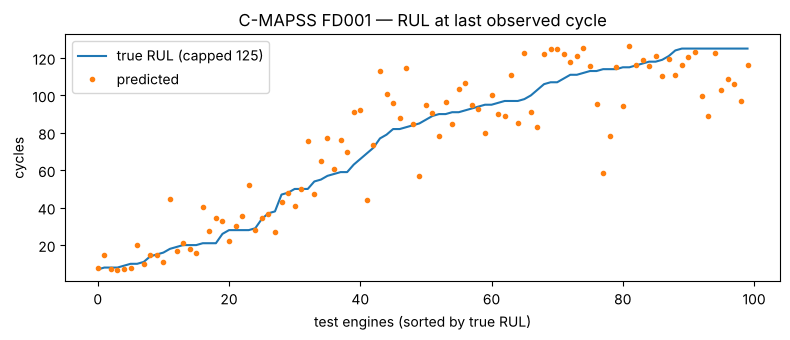

In [11]:
import matplotlib.pyplot as plt
p = res['predictions'].sort_values('rul_true')
plt.figure(figsize=(8, 3.5))
plt.plot(p['rul_true'].to_numpy(), label='true RUL (capped 125)')
plt.plot(p['rul_pred'].to_numpy(), '.', label='predicted')
plt.xlabel('test engines (sorted by true RUL)'); plt.ylabel('cycles'); plt.legend(); plt.title(f'{SOURCE} — RUL at last observed cycle')
plt.tight_layout(); plt.show()

## [GPU — Colab T4] Optional: LSTM sequence model (Zheng et al., 2017 style)
Set `RUN_GPU_CELLS = True` in Colab (Runtime → T4 GPU). On CPU it runs a 1-epoch smoke test only.

In [12]:
RUN_GPU_CELLS = False
import numpy as np
try:
    import torch, torch.nn as nn
except ImportError:
    torch = None
if torch is None:
    print('torch not installed — skip (Colab has it preinstalled)')
else:
    from pdm import features as fe
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    sensors = fe.informative_sensors(train)
    tr = fe.add_rul(train).sort_values(['unit', 'cycle'])
    mu, sd = tr[sensors].mean(), tr[sensors].std() + 1e-8
    W = 30
    def windows(df, with_y=True):
        Xs, ys = [], []
        for _, g in df.groupby('unit'):
            a = ((g[sensors] - mu) / sd).to_numpy(np.float32)
            if len(a) < W: a = np.vstack([np.repeat(a[:1], W - len(a), 0), a])
            if with_y:
                y = g['rul'].to_numpy(np.float32)
                y = np.concatenate([np.repeat(y[:1], max(0, W - len(g))), y])
                for i in range(W, len(a) + 1):
                    Xs.append(a[i - W:i]); ys.append(y[i - 1])
            else:
                Xs.append(a[-W:])
        return np.stack(Xs), (np.array(ys) if with_y else None)
    Xw, yw = windows(tr)
    Xt, _ = windows(test.sort_values(['unit', 'cycle']), with_y=False)
    class LSTMRUL(nn.Module):
        def __init__(self, d):
            super().__init__(); self.lstm = nn.LSTM(d, 64, num_layers=2, batch_first=True, dropout=0.2); self.head = nn.Linear(64, 1)
        def forward(self, x):
            h, _ = self.lstm(x); return self.head(h[:, -1]).squeeze(-1)
    m = LSTMRUL(len(sensors)).to(dev); opt = torch.optim.Adam(m.parameters(), 1e-3)
    epochs = 30 if (RUN_GPU_CELLS and dev == 'cuda') else 1
    ds = torch.utils.data.TensorDataset(torch.from_numpy(Xw), torch.from_numpy(yw))
    dl = torch.utils.data.DataLoader(ds, batch_size=256, shuffle=True)
    for ep in range(epochs):
        m.train()
        for xb, yb in dl:
            opt.zero_grad(); loss = nn.functional.mse_loss(m(xb.to(dev)), yb.to(dev)); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        pred = m(torch.from_numpy(Xt).to(dev)).clamp(min=0).cpu().numpy()
    from pdm.evaluate import rmse
    print(f'LSTM ({epochs} epoch(s), {dev}) test RMSE:', round(rmse(np.minimum(rul, 125), pred), 2))

LSTM (1 epoch(s), cpu) test RMSE: 77.17


## Next steps for the PFE
1. Replace C-MAPSS with the host's sensor/maintenance logs; keep the same `features.py` for training and serving.
2. Add held-out-unit alarm evaluation and a cost model (missed failure vs. false alarm).
3. Calibrate the alarm threshold on business cost, then wrap the model in a FastAPI service + drift monitoring (see proposal C).